In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
print(df.shape)

(7043, 21)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
print(df.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [6]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [7]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [8]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [9]:
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [10]:
df = df.dropna()

print(df.shape)

(7032, 21)


In [11]:
df.drop("customerID", axis=1, inplace=True)

print(df.shape)


(7032, 20)


In [12]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

print(df["Churn"].value_counts())


Churn
0    5163
1    1869
Name: count, dtype: int64


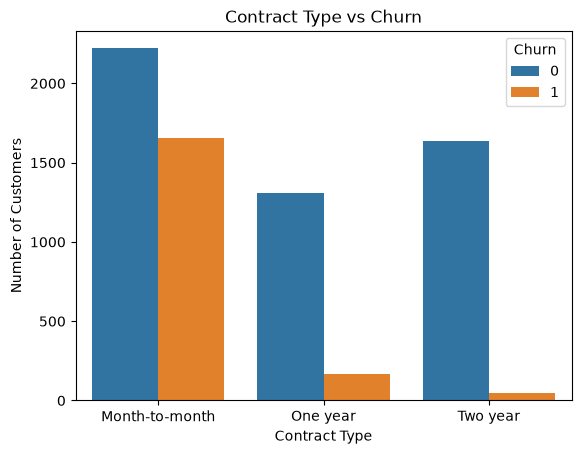

In [13]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()


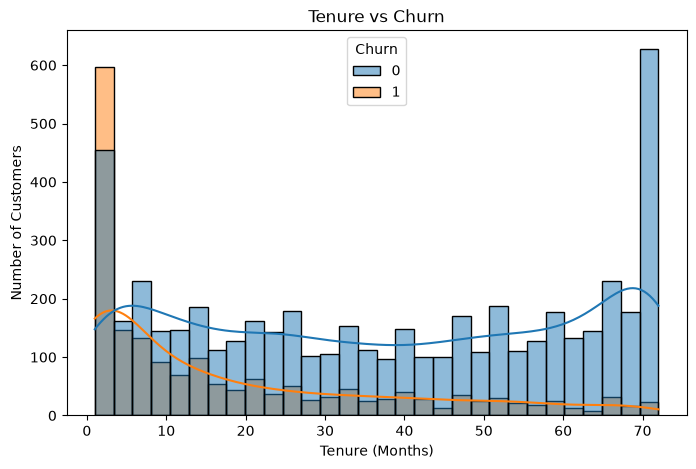

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

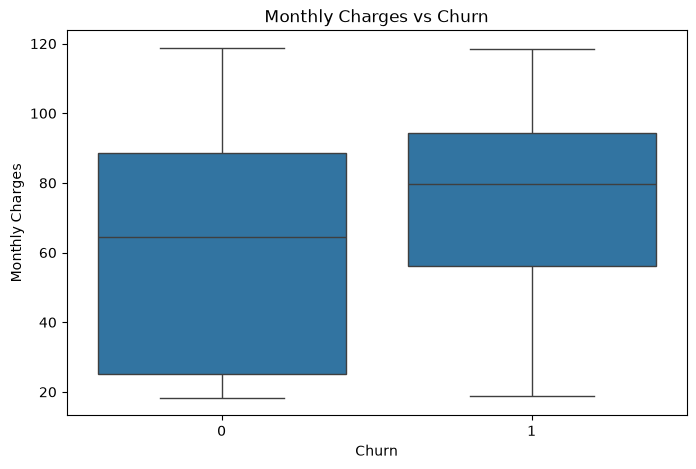

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

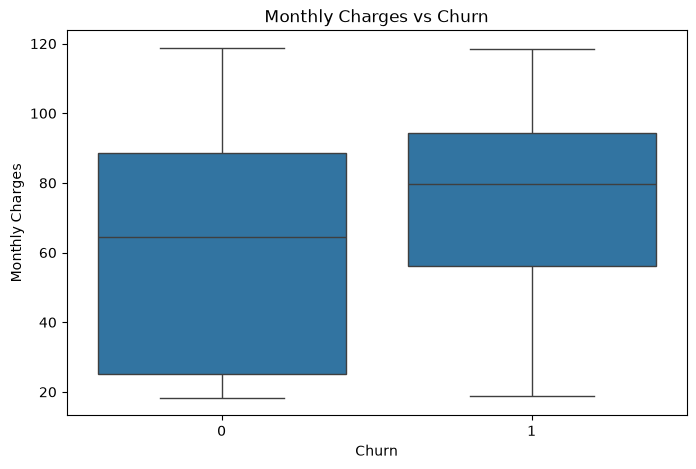

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

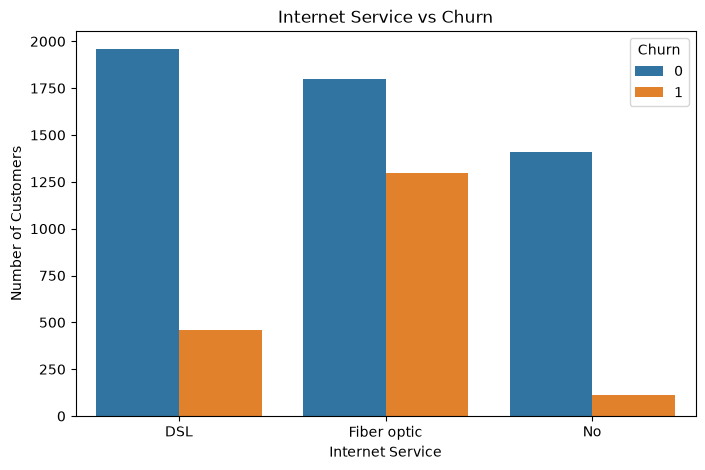

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

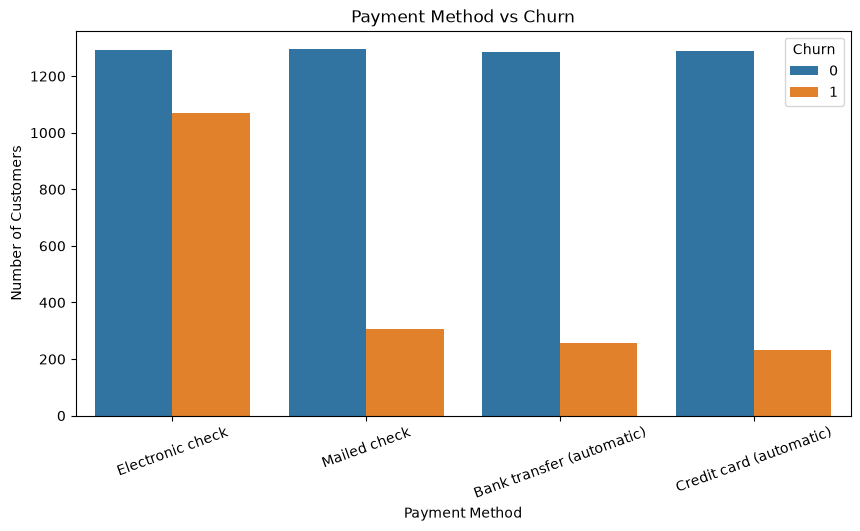

In [18]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

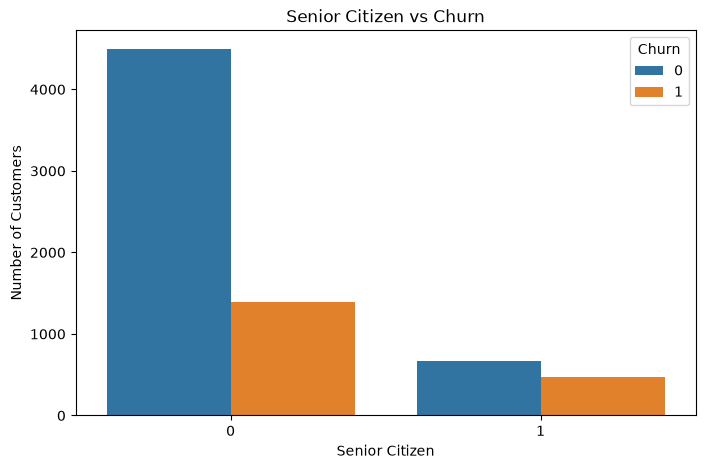

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Senior Citizen vs Churn")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
churn_rate = df.groupby("Contract")["Churn"].mean() * 100

print(churn_rate)

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64


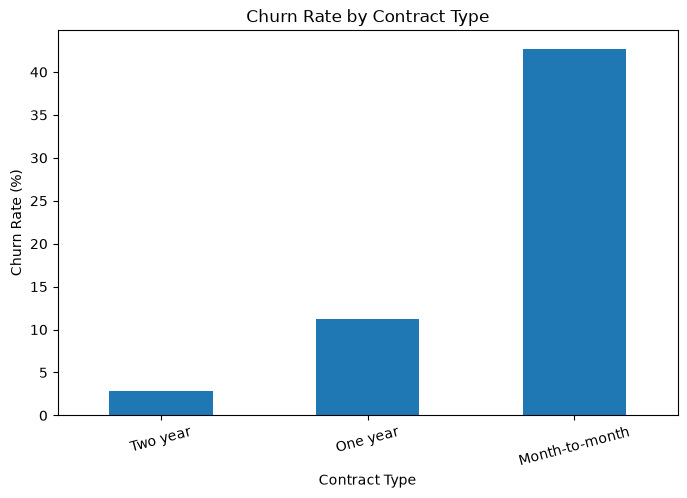

In [21]:
churn_rate.sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.show()

In [22]:
tenure_churn = df.groupby("tenure")["Churn"].mean() * 100

print(tenure_churn)

tenure
1     61.990212
2     51.680672
3     47.000000
4     47.159091
5     48.120301
        ...    
68     9.000000
69     8.421053
70     9.243697
71     3.529412
72     1.657459
Name: Churn, Length: 72, dtype: float64


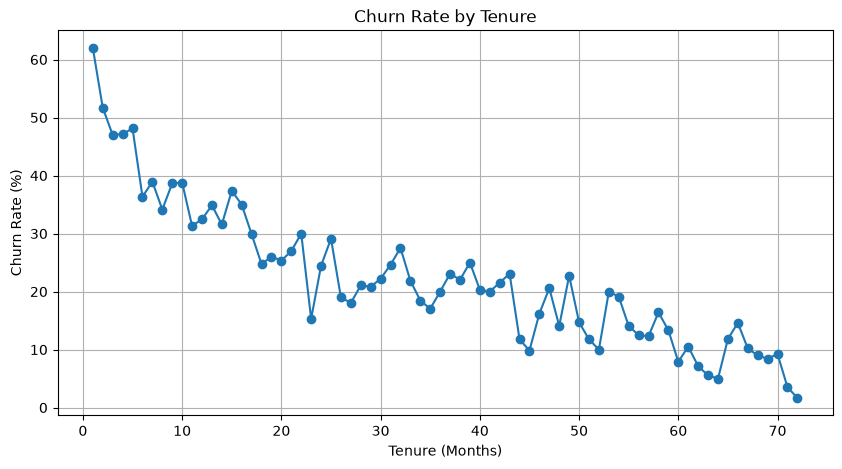

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    tenure_churn.index,
    tenure_churn.values,
    marker="o"
)

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")

plt.grid(True)
plt.show()

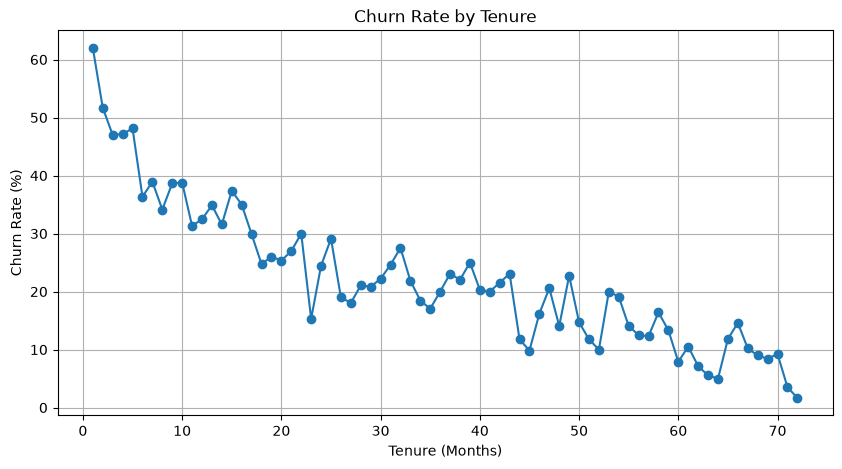

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    tenure_churn.index,
    tenure_churn.values,
    marker="o"
)

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")

plt.grid(True)
plt.show()

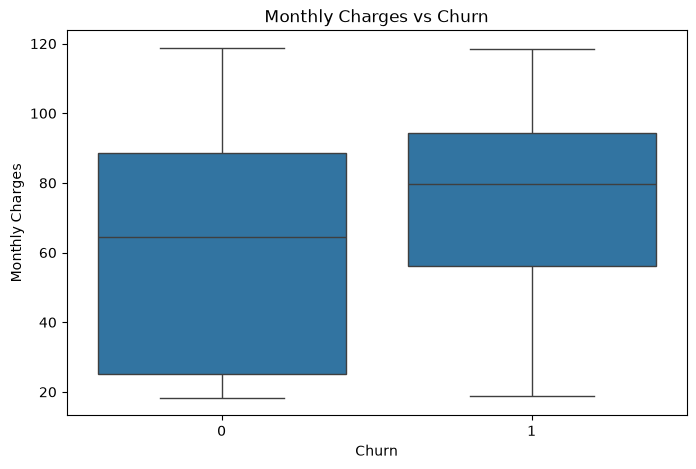

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

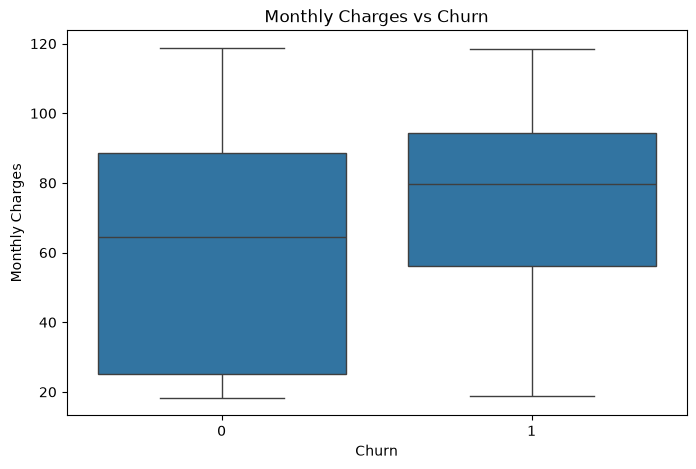

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

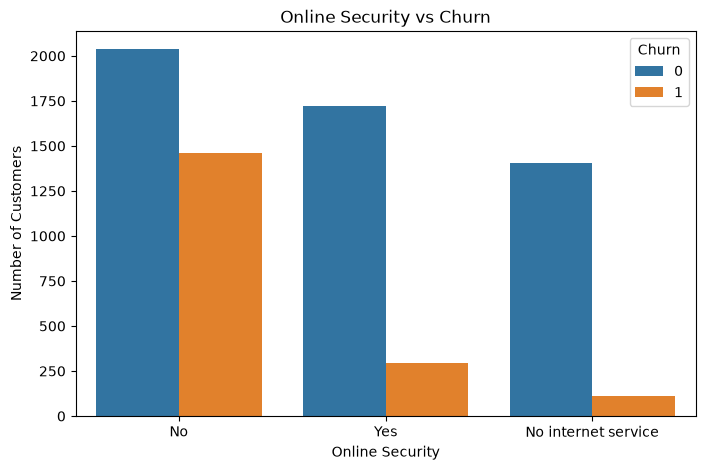

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Online Security vs Churn")
plt.xlabel("Online Security")
plt.ylabel("Number of Customers")

plt.show()

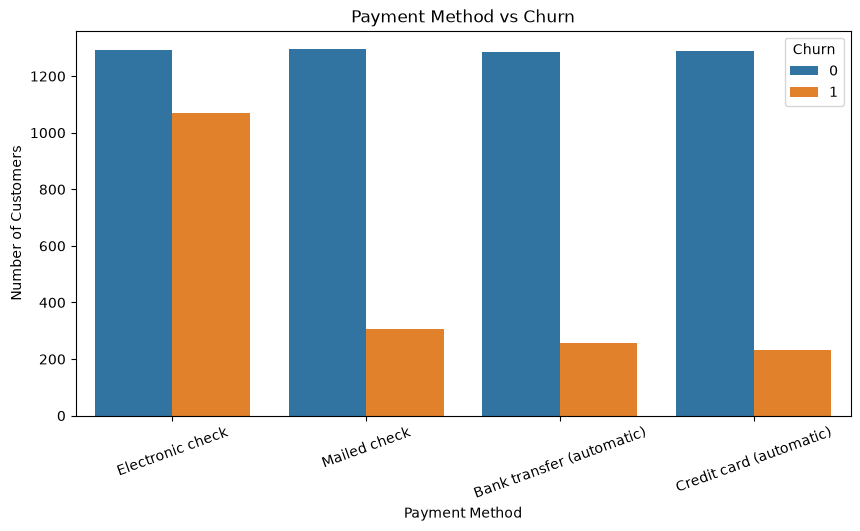

In [28]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

0
plt.show()


In [29]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7032, 19)
y shape: (7032,)


In [30]:
print(X.shape)

(7032, 19)


In [31]:
print(df.shape)

(7032, 20)


In [32]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7032, 19)
y shape: (7032,)


In [33]:
print("Numerical Columns:")
print(X.select_dtypes(include=["int64", "float64"]).columns)

print("\nCategorical Columns:")
print(X.select_dtypes(include=["object"]).columns)

Numerical Columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

Categorical Columns:
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


C:\Users\dell\AppData\Local\Temp\ipykernel_24704\3528556895.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include=["object"]).columns)


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 19)
X_test: (1407, 19)
y_train: (5625,)
y_test: (1407,)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [37]:
numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_cols = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 4
Categorical columns: 15


In [38]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [39]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (5625, 45)
X_test_processed shape: (1407, 45)


In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [42]:
y_pred = logistic_model.predict(X_test_processed)

print(y_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [43]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Logistic Regression Accuracy: 0.8038379530916845
Accuracy (%): 80.38379530916845


[[917 116]
 [160 214]]


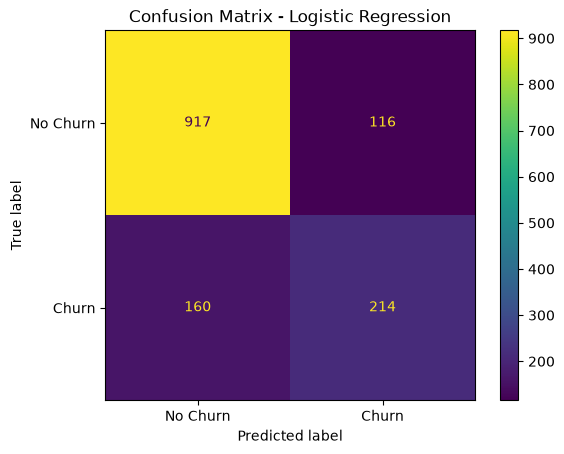

In [44]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Precision: 0.6484848484848484
Recall: 0.5721925133689839
F1-Score: 0.6079545454545454


In [46]:
from sklearn.metrics import roc_auc_score

y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8359290473207676


In [47]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train_processed, y_train)

y_pred_dt = decision_tree.predict(X_test_processed)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.7306325515280739


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Decision Tree Precision:", precision_dt)
print("Decision Tree Recall:", recall_dt)
print("Decision Tree F1-Score:", f1_dt)

Decision Tree Precision: 0.493368700265252
Decision Tree Recall: 0.49732620320855614
Decision Tree F1-Score: 0.49533954727030627


Decision Tree ROC-AUC: 0.6564546438129947


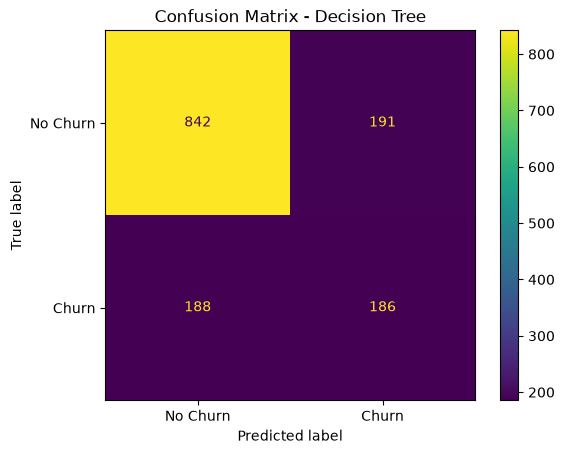

In [49]:
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Churn probability
y_prob_dt = decision_tree.predict_proba(X_test_processed)[:, 1]

# ROC-AUC
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree ROC-AUC:", roc_auc_dt)

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Decision Tree")
plt.show()

In [50]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train_processed, y_train)

y_pred_rf = random_forest.predict(X_test_processed)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.7896233120113717


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Precision
precision_rf = precision_score(y_test, y_pred_rf)

# Recall
recall_rf = recall_score(y_test, y_pred_rf)

# F1-Score
f1_rf = f1_score(y_test, y_pred_rf)

# Churn probability
y_prob_rf = random_forest.predict_proba(X_test_processed)[:, 1]

# ROC-AUC
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Precision:", precision_rf)
print("Random Forest Recall:", recall_rf)
print("Random Forest F1-Score:", f1_rf)
print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest Precision: 0.6344827586206897
Random Forest Recall: 0.4919786096256685
Random Forest F1-Score: 0.5542168674698795
Random Forest ROC-AUC: 0.8139989957084653


In [52]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

y_pred_knn = knn_model.predict(X_test_processed)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.7611940298507462


In [53]:
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

y_prob_knn = knn_model.predict_proba(X_test_processed)[:, 1]
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("KNN Precision:", precision_knn)
print("KNN Recall:", recall_knn)
print("KNN F1-Score:", f1_knn)
print("KNN ROC-AUC:", roc_auc_knn)

KNN Precision: 0.547979797979798
KNN Recall: 0.5802139037433155
KNN F1-Score: 0.5636363636363636
KNN ROC-AUC: 0.7798815557200616


In [54]:
y_pred = logistic_model.predict(X_test_processed)

print(y_pred[:10])

[0 1 0 0 0 0 0 0 1 0]


In [55]:
from sklearn.naive_bayes import GaussianNB

naive_bayes = GaussianNB()

naive_bayes.fit(X_train_processed, y_train)

y_pred_nb = naive_bayes.predict(X_test_processed)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.6823027718550106


In [56]:
precision_nb = precision_score(y_test, y_pred_nb)
recall_nb = recall_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)

y_prob_nb = naive_bayes.predict_proba(X_test_processed)[:, 1]
roc_auc_nb = roc_auc_score(y_test, y_prob_nb)

print("Naive Bayes Precision:", precision_nb)
print("Naive Bayes Recall:", recall_nb)
print("Naive Bayes F1-Score:", f1_nb)
print("Naive Bayes ROC-AUC:", roc_auc_nb)

Naive Bayes Precision: 0.447178002894356
Naive Bayes Recall: 0.8262032085561497
Naive Bayes F1-Score: 0.5802816901408451
Naive Bayes ROC-AUC: 0.8049124868639703


In [57]:
from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

y_pred_svm = svm_model.predict(X_test_processed)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

c:\Users\dell\Downloads\CODING\customer churn prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Accuracy: 0.7917555081734187


In [58]:
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

y_prob_svm = svm_model.predict_proba(X_test_processed)[:, 1]
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print("SVM Precision:", precision_svm)
print("SVM Recall:", recall_svm)
print("SVM F1-Score:", f1_svm)
print("SVM ROC-AUC:", roc_auc_svm)

SVM Precision: 0.6401384083044983
SVM Recall: 0.4946524064171123
SVM F1-Score: 0.5580693815987934
SVM ROC-AUC: 0.7885526295354892


In [59]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_processed, y_train)

y_pred_xgb = xgb_model.predict(X_test_processed)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

XGBoost Accuracy: 0.7860696517412935


In [60]:
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Precision:", precision_xgb)
print("XGBoost Recall:", recall_xgb)
print("XGBoost F1-Score:", f1_xgb)
print("XGBoost ROC-AUC:", roc_auc_xgb)

XGBoost Precision: 0.6130030959752322
XGBoost Recall: 0.5294117647058824
XGBoost F1-Score: 0.5681492109038737
XGBoost ROC-AUC: 0.8323583767749818


In [61]:
results = {
    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    
    "Decision Tree": [
        accuracy_score(y_test, y_pred_dt),
        precision_dt,
        recall_dt,
        f1_dt,
        roc_auc_dt
    ],
    
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_rf,
        recall_rf,
        f1_rf,
        roc_auc_rf
    ],
    
    "KNN": [
        accuracy_score(y_test, y_pred_knn),
        precision_knn,
        recall_knn,
        f1_knn,
        roc_auc_knn
    ],
    
    "Naive Bayes": [
        accuracy_score(y_test, y_pred_nb),
        precision_nb,
        recall_nb,
        f1_nb,
        roc_auc_nb
    ],
    
    "SVM": [
        accuracy_score(y_test, y_pred_svm),
        precision_svm,
        recall_svm,
        f1_svm,
        roc_auc_svm
    ],
    
    "XGBoost": [
        accuracy_score(y_test, y_pred_xgb),
        precision_xgb,
        recall_xgb,
        f1_xgb,
        roc_auc_xgb
    ]
}

results_df = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
).T

print(results_df)

                     Accuracy  Precision    Recall  F1-Score   ROC-AUC
Logistic Regression  0.803838   0.648485  0.572193  0.607955  0.835929
Decision Tree        0.730633   0.493369  0.497326  0.495340  0.656455
Random Forest        0.789623   0.634483  0.491979  0.554217  0.813999
KNN                  0.761194   0.547980  0.580214  0.563636  0.779882
Naive Bayes          0.682303   0.447178  0.826203  0.580282  0.804912
SVM                  0.791756   0.640138  0.494652  0.558069  0.788553
XGBoost              0.786070   0.613003  0.529412  0.568149  0.832358


In [62]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    logistic_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1"
)

print("Cross-Validation F1 Scores:", cv_scores)
print("Mean Cross-Validation F1:", cv_scores.mean())

Cross-Validation F1 Scores: [0.57295374 0.62313433 0.59926471 0.56776557 0.61428571]
Mean Cross-Validation F1: 0.5954808105893297


In [63]:
train_pred = logistic_model.predict(X_train_processed)
test_pred = logistic_model.predict(X_test_processed)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8046222222222222
Testing Accuracy: 0.8038379530916845


In [64]:
train_pred_dt = decision_tree.predict(X_train_processed)
test_pred_dt = decision_tree.predict(X_test_processed)

train_accuracy_dt = accuracy_score(y_train, train_pred_dt)
test_accuracy_dt = accuracy_score(y_test, test_pred_dt)

print("Decision Tree Training Accuracy:", train_accuracy_dt)
print("Decision Tree Testing Accuracy:", test_accuracy_dt)

Decision Tree Training Accuracy: 0.9987555555555555
Decision Tree Testing Accuracy: 0.7306325515280739


In [65]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import joblib
import os

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [66]:
final_pred = final_model.predict(X_test)

final_accuracy = accuracy_score(y_test, final_pred)

print("Final Model Accuracy:", final_accuracy)

Final Model Accuracy: 0.8038379530916845


In [67]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Final model predictions
final_pred = final_model.predict(X_test)

# Probability of churn
final_prob = final_model.predict_proba(X_test)[:, 1]

# Metrics
print("FINAL MODEL RESULTS")
print("-------------------")

print("Accuracy :", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall   :", recall_score(y_test, final_pred))
print("F1-Score :", f1_score(y_test, final_pred))
print("ROC-AUC  :", roc_auc_score(y_test, final_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

FINAL MODEL RESULTS
-------------------
Accuracy : 0.8038379530916845
Precision: 0.6484848484848484
Recall   : 0.5721925133689839
F1-Score : 0.6079545454545454
ROC-AUC  : 0.8359290473207676

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Confusion Matrix:
[[917 116]
 [160 214]]


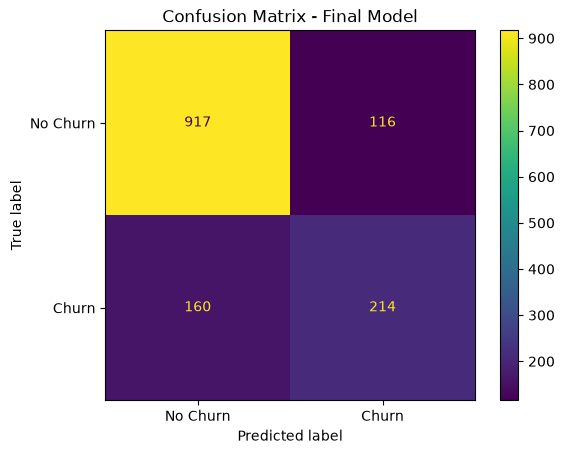

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Confusion Matrix - Final Model")
plt.show()

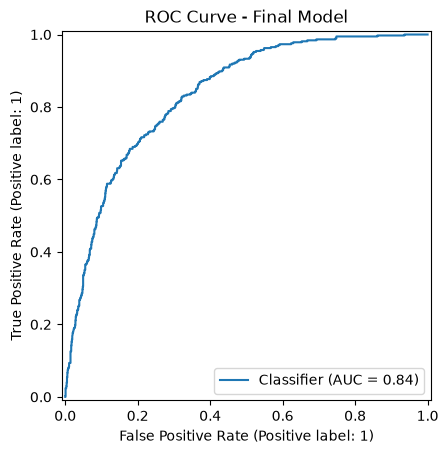

In [70]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    final_prob
)

plt.title("ROC Curve - Final Model")
plt.show()

In [71]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = final_model.named_steps["classifier"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print(feature_importance.head(15))

                                      Feature  Coefficient  \
1                                 num__tenure    -1.352313   
38                     cat__Contract_Two year    -0.779030   
3                           num__TotalCharges     0.644014   
15                   cat__InternetService_DSL    -0.616132   
36               cat__Contract_Month-to-month     0.613846   
16           cat__InternetService_Fiber optic     0.590184   
2                         num__MonthlyCharges    -0.541006   
39                   cat__PaperlessBilling_No    -0.300387   
12                      cat__MultipleLines_No    -0.293470   
17                    cat__InternetService_No    -0.283724   
19    cat__OnlineSecurity_No internet service    -0.283724   
25  cat__DeviceProtection_No internet service    -0.283724   
31       cat__StreamingTV_No internet service    -0.283724   
22      cat__OnlineBackup_No internet service    -0.283724   
28       cat__TechSupport_No internet service    -0.283724   

    Abs

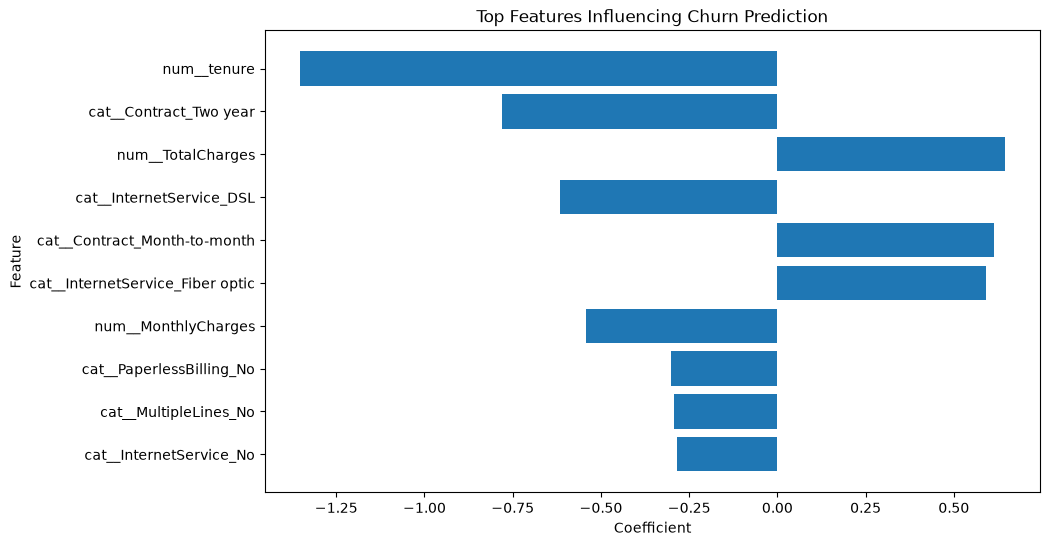

In [72]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top Features Influencing Churn Prediction")
plt.gca().invert_yaxis()

plt.show()

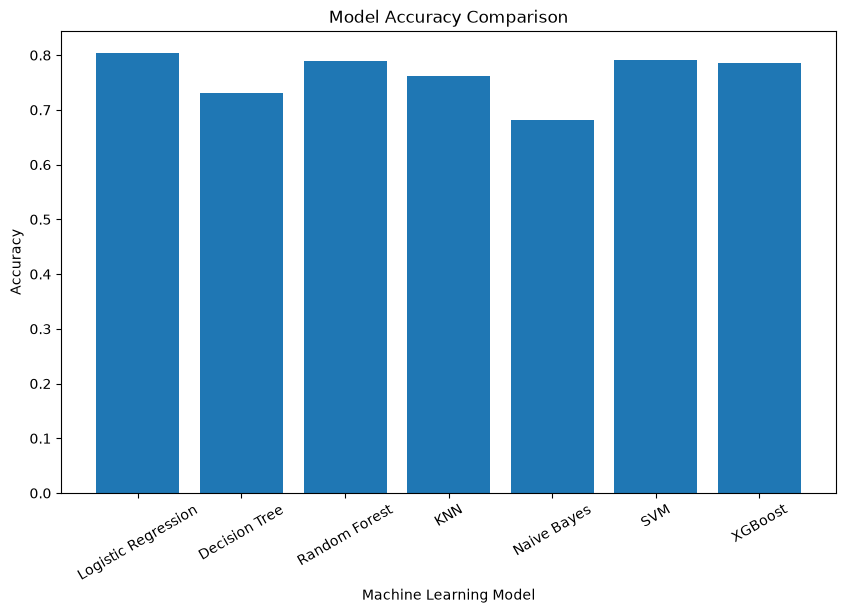

In [73]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df.index,
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)

plt.show()

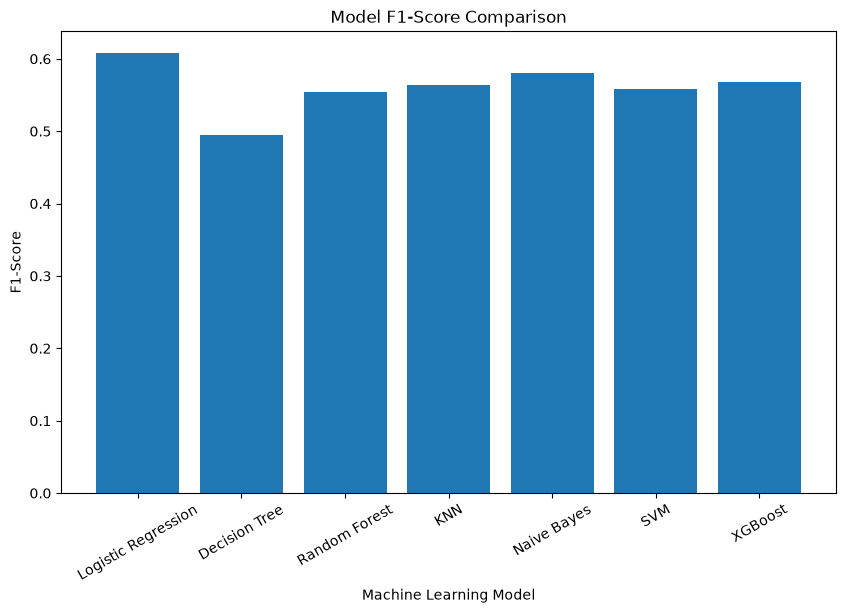

In [74]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df.index,
    results_df["F1-Score"]
)

plt.title("Model F1-Score Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score")

plt.xticks(rotation=30)

plt.show()

In [75]:
best_model_accuracy = results_df["Accuracy"].idxmax()
best_model_f1 = results_df["F1-Score"].idxmax()
best_model_auc = results_df["ROC-AUC"].idxmax()

print("Best Model by Accuracy:", best_model_accuracy)
print("Best Model by F1-Score:", best_model_f1)
print("Best Model by ROC-AUC:", best_model_auc)

Best Model by Accuracy: Logistic Regression
Best Model by F1-Score: Logistic Regression
Best Model by ROC-AUC: Logistic Regression


In [76]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [77]:
final_pred = final_model.predict(X_test)

In [78]:
joblib.dump(
    final_model,
    "../models/churn_model.pkl"
)

['../models/churn_model.pkl']

In [79]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Final model predictions
final_pred = final_model.predict(X_test)

# Churn probability
final_prob = final_model.predict_proba(X_test)[:, 1]

print("========== FINAL MODEL RESULTS ==========")

print("Accuracy :", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall   :", recall_score(y_test, final_pred))
print("F1-Score :", f1_score(y_test, final_pred))
print("ROC-AUC  :", roc_auc_score(y_test, final_prob))

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    final_pred,
    target_names=["No Churn", "Churn"]
))

print("\n========== CONFUSION MATRIX ==========")

print(confusion_matrix(y_test, final_pred))

========== FINAL MODEL RESULTS ==========
Accuracy : 0.8038379530916845
Precision: 0.6484848484848484
Recall   : 0.5721925133689839
F1-Score : 0.6079545454545454
ROC-AUC  : 0.8359290473207676

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


========== CONFUSION MATRIX ==========
[[917 116]
 [160 214]]


In [80]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/churn_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [81]:
print(df.info())

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   str    
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   str    
 3   Dependents        7032 non-null   str    
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   str    
 6   MultipleLines     7032 non-null   str    
 7   InternetService   7032 non-null   str    
 8   OnlineSecurity    7032 non-null   str    
 9   OnlineBackup      7032 non-null   str    
 10  DeviceProtection  7032 non-null   str    
 11  TechSupport       7032 non-null   str    
 12  StreamingTV       7032 non-null   str    
 13  StreamingMovies   7032 non-null   str    
 14  Contract          7032 non-null   str    
 15  PaperlessBilling  7032 non-null   str    
 16  PaymentMethod     7032 non-null   str    
 17  MonthlyChar